# Notebook 02 — Customer Profiling

**Goal:** convert the raw customer and event tables into one interpretable, customer-level profile. This notebook describes customers; it does not perform clustering or assign Loyal/Dormant/Overdue labels.

**Important:** `behavioural_archetype_for_validation` and `synthetic_ground_truth_note` are reference-only fields. They are deliberately excluded from this profile and must never be used as model inputs.

## 1. Mount Google Drive and locate the dataset
Run this notebook in Google Colab. It will use the extracted folder if present; otherwise it will extract the ZIP from MyDrive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import zipfile

MYDRIVE = Path('/content/drive/MyDrive')
DATA_FOLDER_NAME = 'customer_loyalty_synthetic_20k'
DATA_DIR = MYDRIVE / DATA_FOLDER_NAME
ZIP_PATH = MYDRIVE / f'{DATA_FOLDER_NAME}.zip'

if not (DATA_DIR / 'customers.csv').exists():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            f'Could not find {ZIP_PATH}. Check that the ZIP is uploaded directly in MyDrive.'
        )
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(DATA_DIR)

# Handle ZIPs that contain a single nested dataset folder.
if not (DATA_DIR / 'customers.csv').exists():
    matches = list(DATA_DIR.rglob('customers.csv'))
    if not matches:
        raise FileNotFoundError('customers.csv not found after extraction. Check the ZIP folder structure.')
    DATA_DIR = matches[0].parent

PROCESSED_DIR = DATA_DIR / 'processed'
PROCESSED_DIR.mkdir(exist_ok=True)
print('Dataset folder:', DATA_DIR)

Mounted at /content/drive
Dataset folder: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k


## 2. Load source tables

In [2]:
import pandas as pd
import numpy as np

FILES = {
    'customers': 'customers.csv',
    'activity': 'monthly_activity.csv',
    'transactions': 'transactions.csv',
    'billing': 'billing_history.csv',
    'campaigns': 'campaign_interactions.csv',
    'communications': 'communication_history.csv',
}

data = {name: pd.read_csv(DATA_DIR / filename) for name, filename in FILES.items()}
for name, df in data.items():
    print(f'{name:16s}: {df.shape}')

customers = data['customers'].copy()
activity = data['activity'].copy()
transactions = data['transactions'].copy()
billing = data['billing'].copy()
campaigns = data['campaigns'].copy()
communications = data['communications'].copy()

customers       : (20000, 10)
activity        : (240000, 7)
transactions    : (221203, 6)
billing         : (80616, 9)
campaigns       : (64287, 6)
communications  : (50153, 7)


## 3. Understand the customer base

In [3]:
print('Unique customers:', customers['customer_id'].nunique())
display(customers.head())

profile_summary = pd.DataFrame({
    'metric': ['Customers', 'Average tenure (months)', 'Median tenure (months)',
               'Customers with loan (%)', 'Marketing consent (%)'],
    'value': [
        customers['customer_id'].nunique(),
        customers['tenure_months'].mean(),
        customers['tenure_months'].median(),
        customers['has_loan'].astype(str).str.lower().isin(['true','1','yes']).mean() * 100,
        customers['marketing_consent'].astype(str).str.lower().isin(['true','1','yes']).mean() * 100
    ]
})
display(profile_summary)

Unique customers: 20000


,customer_id,join_date,tenure_months,primary_product,customer_status,preferred_channel,marketing_consent,monthly_contact_cap,statement_cycle,has_loan
0,CUST000001,2026-07-04,4,Premium,New,App,True,4,Monthly,False
1,CUST000002,2023-09-18,38,Current,Active,Email,True,4,Monthly,False
2,CUST000003,2026-05-05,6,Salary,Active,App,True,5,Monthly,False
3,CUST000004,2026-07-04,4,Savings,New,Email,True,2,Monthly,False
4,CUST000005,2024-08-13,27,Salary,Active,WhatsApp,True,4,Monthly,False


,metric,value
0,Customers,20000.0000
1,Average tenure (months),51.1138
2,Median tenure (months),49.0000
3,Customers with loan (%),33.5900
4,Marketing consent (%),90.8450


## 4. Build event-level aggregates

In [4]:
# Activity: summarize the observed monthly behaviour for each customer.
activity_agg = activity.groupby('customer_id').agg(
    observed_months=('activity_month', 'nunique'),
    avg_active_days=('active_days', 'mean'),
    avg_login_count=('login_count', 'mean'),
    avg_app_sessions=('app_sessions', 'mean'),
    avg_service_usage=('service_usage_count', 'mean'),
    avg_engagement_score=('engagement_score', 'mean'),
    latest_engagement_score=('engagement_score', 'last'),
).reset_index()

# Transactions: use successful transactions for monetary behaviour.
transactions['transaction_date'] = pd.to_datetime(transactions['transaction_date'], errors='coerce')
transactions['is_successful'] = transactions['transaction_status'].astype(str).str.lower().eq('successful')
success_tx = transactions[transactions['is_successful']].copy()
transaction_agg = success_tx.groupby('customer_id').agg(
    successful_transaction_count=('transaction_id', 'count'),
    total_transaction_value_inr=('amount_inr', 'sum'),
    avg_transaction_value_inr=('amount_inr', 'mean'),
    median_transaction_value_inr=('amount_inr', 'median'),
    last_transaction_date=('transaction_date', 'max'),
).reset_index()

# Billing: retain billing measures separately from behavioural engagement.
billing_agg = billing.groupby('customer_id').agg(
    bill_count=('bill_id', 'count'),
    total_amount_due_inr=('amount_due_inr', 'sum'),
    total_amount_paid_inr=('amount_paid_inr', 'sum'),
    overdue_bill_count=('billing_status', lambda s: s.astype(str).str.lower().eq('overdue').sum()),
    avg_days_overdue=('days_overdue', 'mean'),
    max_days_overdue=('days_overdue', 'max'),
).reset_index()

# Campaign response: Accepted / total campaign interactions.
campaign_agg = campaigns.groupby('customer_id').agg(
    campaigns_received=('interaction_id', 'count'),
    campaigns_accepted=('response_status', lambda s: s.astype(str).str.lower().eq('accepted').sum()),
).reset_index()
campaign_agg['campaign_acceptance_rate'] = (
    campaign_agg['campaigns_accepted'] / campaign_agg['campaigns_received'].replace(0, np.nan)
)

# Communications: summarize contact volume and delivery/engagement outcomes.
communication_agg = communications.groupby('customer_id').agg(
    communication_count=('communication_id', 'count'),
    delivered_count=('delivery_status', lambda s: s.astype(str).str.lower().isin(['delivered','opened','clicked']).sum()),
    opened_count=('delivery_status', lambda s: s.astype(str).str.lower().isin(['opened','clicked']).sum()),
    clicked_count=('delivery_status', lambda s: s.astype(str).str.lower().eq('clicked').sum()),
).reset_index()
communication_agg['communication_delivery_rate'] = (
    communication_agg['delivered_count'] / communication_agg['communication_count'].replace(0, np.nan)
)
communication_agg['communication_engagement_rate'] = (
    communication_agg['opened_count'] / communication_agg['communication_count'].replace(0, np.nan)
)

print('Aggregates created:', [len(x) for x in [activity_agg, transaction_agg, billing_agg, campaign_agg, communication_agg]])

Aggregates created: [20000, 19839, 6718, 19170, 18456]


## 5. Combine into one customer profile

In [5]:
customer_profile = customers.copy()
for agg in [activity_agg, transaction_agg, billing_agg, campaign_agg, communication_agg]:
    customer_profile = customer_profile.merge(agg, on='customer_id', how='left', validate='one_to_one')

# Snapshot date is the latest date observed across transaction, billing and campaign/communication events.
date_candidates = [
    pd.to_datetime(transactions['transaction_date'], errors='coerce').max(),
    pd.to_datetime(billing['due_date'], errors='coerce').max(),
    pd.to_datetime(campaigns['interaction_date'], errors='coerce').max(),
    pd.to_datetime(communications['communication_date'], errors='coerce').max(),
]
snapshot_date = max(d for d in date_candidates if pd.notna(d))
customer_profile['last_transaction_date'] = pd.to_datetime(customer_profile['last_transaction_date'], errors='coerce')
customer_profile['transaction_recency_days'] = (snapshot_date - customer_profile['last_transaction_date']).dt.days

count_cols = ['observed_months','successful_transaction_count','bill_count','overdue_bill_count',
              'campaigns_received','campaigns_accepted','communication_count','delivered_count',
              'opened_count','clicked_count']
for col in count_cols:
    if col in customer_profile.columns:
        customer_profile[col] = customer_profile[col].fillna(0)

print('Snapshot date:', snapshot_date.date())
print('Profile shape:', customer_profile.shape)
display(customer_profile.head())

Snapshot date: 2026-11-16
Profile shape: (20000, 38)


,customer_id,join_date,tenure_months,primary_product,customer_status,preferred_channel,marketing_consent,monthly_contact_cap,statement_cycle,has_loan,...,campaigns_received,campaigns_accepted,campaign_acceptance_rate,communication_count,delivered_count,opened_count,clicked_count,communication_delivery_rate,communication_engagement_rate,transaction_recency_days
0,CUST000001,2026-07-04,4,Premium,New,App,True,4,Monthly,False,...,4.0,0.0,0.0,3.0,2.0,1.0,0.0,0.666667,0.333333,54.0
1,CUST000002,2023-09-18,38,Current,Active,Email,True,4,Monthly,False,...,5.0,2.0,0.4,2.0,2.0,1.0,0.0,1.000000,0.500000,37.0
2,CUST000003,2026-05-05,6,Salary,Active,App,True,5,Monthly,False,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.000000,0.000000,32.0
3,CUST000004,2026-07-04,4,Savings,New,Email,True,2,Monthly,False,...,1.0,0.0,0.0,2.0,0.0,0.0,0.0,0.000000,0.000000,62.0
4,CUST000005,2024-08-13,27,Salary,Active,WhatsApp,True,4,Monthly,False,...,4.0,2.0,0.5,3.0,3.0,2.0,2.0,1.000000,0.666667,16.0


## 6. Profile customers by useful business dimensions

In [6]:
def grouped_profile(df, group_col):
    return df.groupby(group_col, dropna=False).agg(
        customers=('customer_id', 'nunique'),
        avg_tenure_months=('tenure_months', 'mean'),
        avg_engagement_score=('avg_engagement_score', 'mean'),
        avg_monthly_logins=('avg_login_count', 'mean'),
        avg_transaction_value_inr=('total_transaction_value_inr', 'mean'),
        avg_campaign_acceptance_rate=('campaign_acceptance_rate', 'mean'),
        avg_overdue_bills=('overdue_bill_count', 'mean'),
    ).reset_index()

for dimension in ['primary_product', 'customer_status', 'preferred_channel', 'has_loan']:
    print(f'\nProfile by {dimension}')
    display(grouped_profile(customer_profile, dimension).round(2))


Profile by primary_product


,primary_product,customers,avg_tenure_months,avg_engagement_score,avg_monthly_logins,avg_transaction_value_inr,avg_campaign_acceptance_rate,avg_overdue_bills
0,Current,2448,50.44,55.11,18.25,3636.77,0.31,0.68
1,Premium,3006,51.43,54.98,18.16,3660.01,0.30,0.68
2,Salary,4604,50.89,55.53,18.25,3632.94,0.31,0.64
3,Savings,7573,51.15,54.83,18.00,3627.05,0.30,0.68
4,Student,2369,51.72,54.78,17.93,3662.07,0.30,0.66



Profile by customer_status


,customer_status,customers,avg_tenure_months,avg_engagement_score,avg_monthly_logins,avg_transaction_value_inr,avg_campaign_acceptance_rate,avg_overdue_bills
0,Active,13900,62.26,66.81,22.81,4475.53,0.37,0.47
1,Inactive,3283,45.65,10.44,2.44,1235.42,0.05,1.57
2,New,2817,2.49,48.97,13.10,2176.02,0.30,0.57



Profile by preferred_channel


,preferred_channel,customers,avg_tenure_months,avg_engagement_score,avg_monthly_logins,avg_transaction_value_inr,avg_campaign_acceptance_rate,avg_overdue_bills
0,App,5996,50.67,55.28,18.12,3655.51,0.30,0.68
1,Email,5950,51.78,55.22,18.09,3630.92,0.31,0.66
2,SMS,5000,51.26,55.03,18.20,3674.45,0.30,0.65
3,WhatsApp,3054,50.46,54.24,17.92,3562.49,0.31,0.68



Profile by has_loan


,has_loan,customers,avg_tenure_months,avg_engagement_score,avg_monthly_logins,avg_transaction_value_inr,avg_campaign_acceptance_rate,avg_overdue_bills
0,False,13282,51.04,55.08,18.11,3617.21,0.31,0.00
1,True,6718,51.26,54.98,18.08,3681.20,0.30,1.99


## 7. Missingness and profile checks

In [7]:
missing_profile = (customer_profile.isna().mean() * 100).sort_values(ascending=False).rename('missing_pct').reset_index()
missing_profile.columns = ['column', 'missing_pct']
display(missing_profile.head(20).round(2))

print('Duplicate customer IDs:', customer_profile['customer_id'].duplicated().sum())
print('Rows match customer master:', len(customer_profile) == customers['customer_id'].nunique())
print('Customer ID unique:', customer_profile['customer_id'].is_unique)

,column,missing_pct
0,max_days_overdue,66.41
1,avg_days_overdue,66.41
2,total_amount_due_inr,66.41
3,total_amount_paid_inr,66.41
4,communication_delivery_rate,7.72
5,communication_engagement_rate,7.72
6,campaign_acceptance_rate,4.15
7,avg_transaction_value_inr,0.80
8,transaction_recency_days,0.80
9,last_transaction_date,0.80


Duplicate customer IDs: 0
Rows match customer master: True
Customer ID unique: True


## 8. Visualize profile distributions

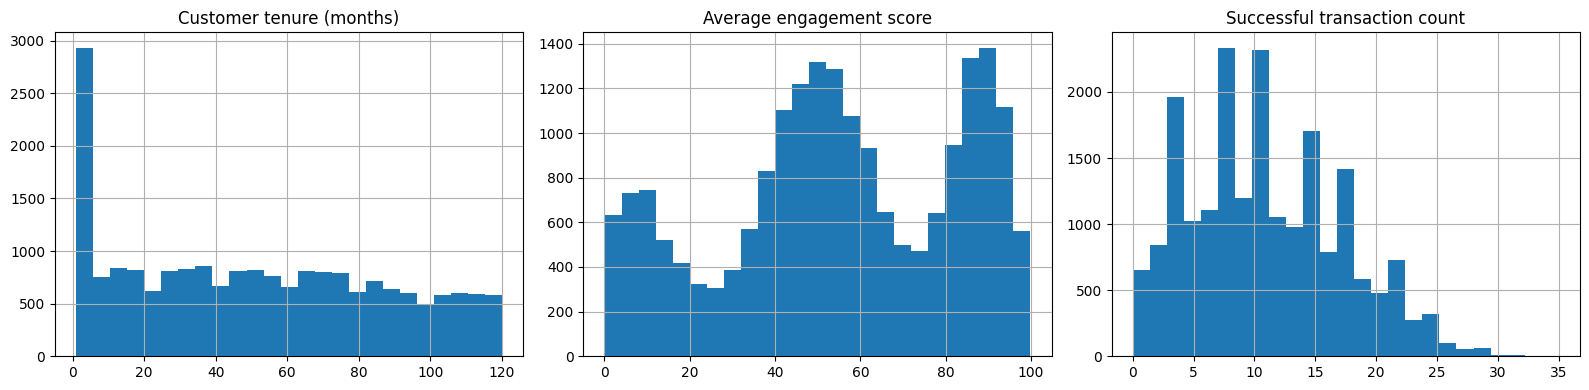

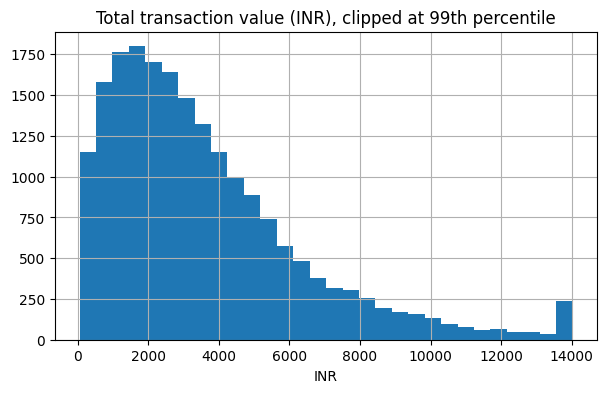

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
customer_profile['tenure_months'].hist(ax=axes[0], bins=25)
axes[0].set_title('Customer tenure (months)')
customer_profile['avg_engagement_score'].dropna().hist(ax=axes[1], bins=25)
axes[1].set_title('Average engagement score')
customer_profile['successful_transaction_count'].hist(ax=axes[2], bins=25)
axes[2].set_title('Successful transaction count')
plt.tight_layout()
plt.show()

customer_profile['total_transaction_value_inr'].dropna().clip(upper=customer_profile['total_transaction_value_inr'].quantile(0.99)).hist(bins=30, figsize=(7,4))
plt.title('Total transaction value (INR), clipped at 99th percentile')
plt.xlabel('INR')
plt.show()

## 9. Export the customer profile

In [9]:
# Exclude synthetic validation/ground-truth columns by design.
for forbidden in ['behavioural_archetype_for_validation', 'synthetic_ground_truth_note']:
    if forbidden in customer_profile.columns:
        customer_profile = customer_profile.drop(columns=forbidden)

output_path = PROCESSED_DIR / 'customer_profile.csv'
customer_profile.to_csv(output_path, index=False)
print('Saved:', output_path)
print('Final profile dimensions:', customer_profile.shape)

Saved: /content/drive/MyDrive/customer_loyalty_synthetic_20k/customer_loyalty_synthetic_20k/processed/customer_profile.csv
Final profile dimensions: (20000, 38)


## 10. What we achieved and what comes next

At this stage we have a **descriptive customer profile** assembled from the customer master and event histories. Billing indicators remain separate from behavioural indicators: a customer may be highly engaged and still have an overdue bill.

**Next notebook — 03 Feature Engineering:** create modelling-ready behavioural features, handle skew/outliers and missing values, select appropriate features, and prepare a clean matrix for clustering. We will not use `customer_id`, marketing/operational controls, or synthetic validation labels as clustering inputs.